# Proyecto Individual Integrador — Predicción de Reingresos Hospitalarios en Pacientes con Diabetes
### Cierre y Examen Final de Ciencia de Datos

**Alumna:** Luciana Chutte  
**Materia:** Ciencia de Datos (INA)  
**Organización analizada:** Red Sanatorial de Alta Complejidad — Consorcio Clínico (*Health Facts* EHR, 130 hospitales)  
**Datasets:** `diabetic_data.csv` (101.766 episodios de internación, 50 variables) e `IDS_mapping.csv` (diccionario maestro de admisión, origen y egreso).

---
## 0. Diagnóstico Organizacional y Propuesta (Etapa 1 — Las Dos Capas)

### 0.1 Contexto de la Organización y Cultura de Datos
Elegí trabajar sobre una **Red Hospitalaria de Alta Complejidad** que centraliza los registros clínicos electrónicos (HIS/ERP) de episodios de internación de pacientes con diabetes. Al analizar cómo opera la organización, noto que la toma de decisiones al momento del alta hospitalaria es **reactiva y fragmentada**:
* Cada servicio médico (Clínica Médica, Cardiología, Cirugía, Guardia) decide el alta y el plan farmacológico basándose en la intuición clínica individual del profesional de turno.
* No existe visibilidad unificada del historial de reingresos previos del paciente ni alertas automatizadas sobre la falta de controles clave de laboratorio, como la **hemoglobina glicosilada (`A1Cresult`)**.

### 0.2 Las Dos Capas del Problema
1. **CAPA 1 — DIAGNÓSTICO (Qué está roto hoy):**  
   Identifiqué una **deficiencia estructural en la gobernanza e integración de datos clínicos**. Los sistemas transaccionales de admisión, laboratorio y farmacia vuelcan registros sin validación de completitud ni cruce con los catálogos maestros (`IDS_mapping.csv`). Esto genera faltantes masivos (`weight` con 96,86% de omisión codificada como `?`), códigos de alta sin mapear, múltiples internaciones del mismo paciente (`patient_nbr`) tratadas como episodios aislados y pacientes fallecidos (`Expired` / `Hospice`) mezclados en la misma bolsa analítica que los pacientes dados de alta a domicilio.
2. **CAPA 2 — PROPUESTA (Qué área de datos abrir):**  
   Propongo crear el área de **Analítica Clínica y Seguimiento Post-Alta**, cuyo objetivo es predecir al momento del egreso la probabilidad de **reingreso hospitalario temprano (`<30` días)** y disponibilizar un tablero ejecutivo en Power BI junto con un simulador operativo para el **Coordinador de Gestión de Camas y Alta Hospitalaria**.

### 0.3 Justificación de Prioridad: ¿Cuál atendí primero?
**Decisión:** Prioricé resolver primero la **Capa 1 (Saneamiento, Integración de Diccionarios y Gobernanza en un Data Mart clínico)** antes de entrenar y desplegar el modelo predictivo de la Capa 2.  
**Fundamento técnico y de negocio:**
* **Prevención de *Data Leakage*:** Si hubiera modelado directamente sobre los 101.766 encuentros sin consolidar por paciente único (`patient_nbr`), un mismo paciente aparecería simultáneamente en entrenamiento y evaluación, inflando artificialmente las métricas.
* **Eliminación de sesgo clínico crítico:** Los pacientes fallecidos durante la internación tienen probabilidad biológica cero de reingresar (`readmitted = NO`). No excluirlos en el ETL habría hecho que el modelo asocie cuadros de extrema gravedad con "bajo riesgo de reingreso".
* **Quick Win para Dirección Médica:** Un dataset auditado y normalizado permitió alimentar inmediatamente el dashboard de Power BI para visibilizar la brecha de control de A1C por especialidad mientras calibraba el modelo de Machine Learning.

---
## 1. Importación de librerías

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilo con paleta color pastel
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("pastel")
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', lambda x: f'{x:.2f}')
print("Librerías importadas correctamente sin advertencias.")

Librerías importadas correctamente sin advertencias.


## 2. Carga de datos e inspección inicial

In [2]:
df = pd.read_csv('diabetic_data.csv')
print(f"Dimensiones del dataset original: {df.shape[0]:,} filas x {df.shape[1]} columnas")
display(df.head(3))

Dimensiones del dataset original: 101,766 filas x 50 columnas


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO


In [3]:
# Inspección del diccionario maestro IDS_mapping.csv
with open('IDS_mapping.csv', 'r', encoding='utf-8') as f:
    print(f.read()[:1000])

admission_type_id,description
1,Emergency
2,Urgent
3,Elective
4,Newborn
5,Not Available
6,NULL
7,Trauma Center
8,Not Mapped
,
discharge_disposition_id,description
1,Discharged to home
2,Discharged/transferred to another short term hospital
3,Discharged/transferred to SNF
4,Discharged/transferred to ICF
5,Discharged/transferred to another type of inpatient care institution
6,Discharged/transferred to home with home health service
7,Left AMA
8,Discharged/transferred to home under care of Home IV provider
9,Admitted as an inpatient to this hospital
10,Neonate discharged to another hospital for neonatal aftercare
11,Expired
12,Still patient or expected to return for outpatient services
13,Hospice / home
14,Hospice / medical facility
15,Discharged/transferred within this institution to Medicare approved swing bed
16,Discharged/transferred/referred another institution for outpatient services
17,Discharged/transferred/referred to this institution for outpatient services
18,NULL
19,"Expired at

---
## 3. Auditoría de calidad de datos — Las 6 Dimensiones (Bloque 2)

En este dataset clínico, los valores faltantes se presentan bajo **tres mecanismos distintos**:
1. Valores `NaN` nativos (en `max_glu_serum` y `A1Cresult`, donde la palabra `'None'` en el CSV original representa que el estudio no fue solicitado).
2. Caracteres comodín `'?'` insertados por el sistema HIS/ERP legado (`weight`, `medical_specialty`, `payer_code`, `race`, `diag_1`, `diag_2`, `diag_3`).
3. Códigos numéricos que significan `NULL`, `Not Available`, `Not Mapped` o `Unknown/Invalid` según `IDS_mapping.csv`.

### 3.1 Completitud (¿faltan datos explícitos u ocultos?)

In [4]:
na_nativos = df.isna().sum()
signos_pregunta = (df == '?').sum()
total_faltantes = na_nativos + signos_pregunta
pct_faltantes = (total_faltantes / len(df) * 100).round(2)

tabla_completitud = pd.DataFrame({
    'NaN_Nativos': na_nativos,
    'Codificados_como_?': signos_pregunta,
    'Total_Faltantes': total_faltantes,
    'Porcentaje_%': pct_faltantes
}).query('Total_Faltantes > 0').sort_values('Porcentaje_%', ascending=False)

print("=== Faltantes explícitos ('NaN' y '?') ===")
display(tabla_completitud)

faltantes_adm_type = df['admission_type_id'].isin([5, 6, 8]).sum()
faltantes_discharge = df['discharge_disposition_id'].isin([18, 25, 26]).sum()
faltantes_adm_source = df['admission_source_id'].isin([9, 15, 17, 20, 21]).sum()

print("\n=== Faltantes ocultos en tablas maestras (IDS_mapping.csv) ===")
print(f"- admission_type_id (códigos 5, 6, 8): {faltantes_adm_type:,} ({faltantes_adm_type/len(df)*100:.2f}%)")
print(f"- admission_source_id (códigos 9, 15, 17, 20, 21): {faltantes_adm_source:,} ({faltantes_adm_source/len(df)*100:.2f}%)")
print(f"- discharge_disposition_id (códigos 18, 25, 26): {faltantes_discharge:,} ({faltantes_discharge/len(df)*100:.2f}%)")

=== Faltantes explícitos ('NaN' y '?') ===


,NaN_Nativos,Codificados_como_?,Total_Faltantes,Porcentaje_%
weight,0,98569,98569,96.86
max_glu_serum,96420,0,96420,94.75
A1Cresult,84748,0,84748,83.28
medical_specialty,0,49949,49949,49.08
payer_code,0,40256,40256,39.56
race,0,2273,2273,2.23
diag_3,0,1423,1423,1.40
diag_2,0,358,358,0.35
diag_1,0,21,21,0.02



=== Faltantes ocultos en tablas maestras (IDS_mapping.csv) ===
- admission_type_id (códigos 5, 6, 8): 10,396 (10.22%)
- admission_source_id (códigos 9, 15, 17, 20, 21): 7,067 (6.94%)
- discharge_disposition_id (códigos 18, 25, 26): 4,680 (4.60%)


### 3.2 Unicidad (¿hay registros o pacientes duplicados?)

In [5]:
n_encounters = df['encounter_id'].nunique()
n_patients = df['patient_nbr'].nunique()
pacientes_recurrentes = (df['patient_nbr'].value_counts() > 1).sum()

print(f"Total de filas:                       {len(df):,}")
print(f"Episodios únicos (encounter_id):      {n_encounters:,}")
print(f"Pacientes únicos (patient_nbr):       {n_patients:,}")
print(f"Pacientes con >1 internación en base: {pacientes_recurrentes:,} ({pacientes_recurrentes/n_patients*100:.2f}% del padrón)")

Total de filas:                       101,766
Episodios únicos (encounter_id):      101,766
Pacientes únicos (patient_nbr):       71,518
Pacientes con >1 internación en base: 16,773 (23.45% del padrón)


**Decisión para el ETL:** Aunque `encounter_id` es único al 100%, existen 16.773 pacientes con múltiples episodios. Para respetar la independencia estadística entre observaciones y evitar *data leakage* entre entrenamiento y validación, en el ETL ordené cronológicamente por `encounter_id` y conservé el primer episodio de cada paciente (`patient_nbr`), preservando su historial en las variables de utilización previa.

### 3.3 Consistencia (¿los datos son coherentes con las reglas de negocio?)

In [6]:
codigos_fallecidos_hospice = [11, 13, 14, 19, 20, 21]
df_fallecidos = df[df['discharge_disposition_id'].isin(codigos_fallecidos_hospice)]
print(f"Episodios con alta por fallecimiento o Hospice (IDs {codigos_fallecidos_hospice}): {len(df_fallecidos):,} ({len(df_fallecidos)/len(df)*100:.2f}%)")
print("Distribución de 'readmitted' en pacientes fallecidos/hospice:")
print(df_fallecidos['readmitted'].value_counts())

inconsistencia_med = df[(df['diabetesMed'] == 'No') & (df['change'] == 'Ch')]
print(f"\nInconsistencias entre diabetesMed='No' y change='Ch': {len(inconsistencia_med)}")

Episodios con alta por fallecimiento o Hospice (IDs [11, 13, 14, 19, 20, 21]): 2,423 (2.38%)
Distribución de 'readmitted' en pacientes fallecidos/hospice:
readmitted
NO     2337
<30      43
>30      43
Name: count, dtype: int64

Inconsistencias entre diabetesMed='No' y change='Ch': 0


### 3.4 Validez y Varianza Cero

In [7]:
print("Distribución de gender:")
print(df['gender'].value_counts())

med_cols = ['metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 
            'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 
            'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 
            'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 
            'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone']

constantes = [c for c in med_cols if df[c].nunique() == 1]
print(f"\nColumnas de medicación con varianza cero (100% valor 'No'): {constantes}")

Distribución de gender:
gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64

Columnas de medicación con varianza cero (100% valor 'No'): ['examide', 'citoglipton']


---
## 4. Clasificación de Datos Faltantes: MCAR, MAR y MNAR (Bloque 2)

1. **`A1Cresult` (83,28% ausente) y `max_glu_serum` (94,75% ausente) $
ightarrow$ MNAR (*Missing Not At Random*):**  
   En la práctica hospitalaria, el médico solicita el estudio de hemoglobina glicosilada cuando sospecha mal control metabólico o debut diabético. El hecho de que no se haya medido contiene señal clínica sobre la decisión médica. En el ETL lo recodifiqué como categoría explícita `'No_Medido'` y creé el indicador binario `flag_a1c_medido`.
2. **`weight` (96,86% ausente), `medical_specialty` (49,08% ausente) y `payer_code` (39,56% ausente) $
ightarrow$ MAR (*Missing At Random*):**  
   La omisión depende de los protocolos administrativos de cada centro. Como `weight` supera el 96% de faltantes, descarté la columna bruta pero conservé el indicador `flag_peso_registrado`.

In [8]:
df['a1c_solicitado'] = df['A1Cresult'].notna().astype(int)
resumen_a1c = df.groupby('admission_type_id').agg(
    total_episodios=('encounter_id', 'count'),
    pct_a1c_medido=('a1c_solicitado', lambda x: round(x.mean()*100, 2)),
    dias_internacion_prom=('time_in_hospital', 'mean')
)
display(resumen_a1c)

,total_episodios,pct_a1c_medido,dias_internacion_prom
admission_type_id,,,
1,53990,19.20,4.38
2,18480,17.28,4.61
3,18869,10.24,4.32
4,10,20.00,3.20
5,4785,9.30,3.95
6,5291,19.16,4.58
7,21,19.05,4.86
8,320,18.44,3.06


---
## 5. Detección de Sesgos y Desbalance del Target (Bloques 2 y 5)

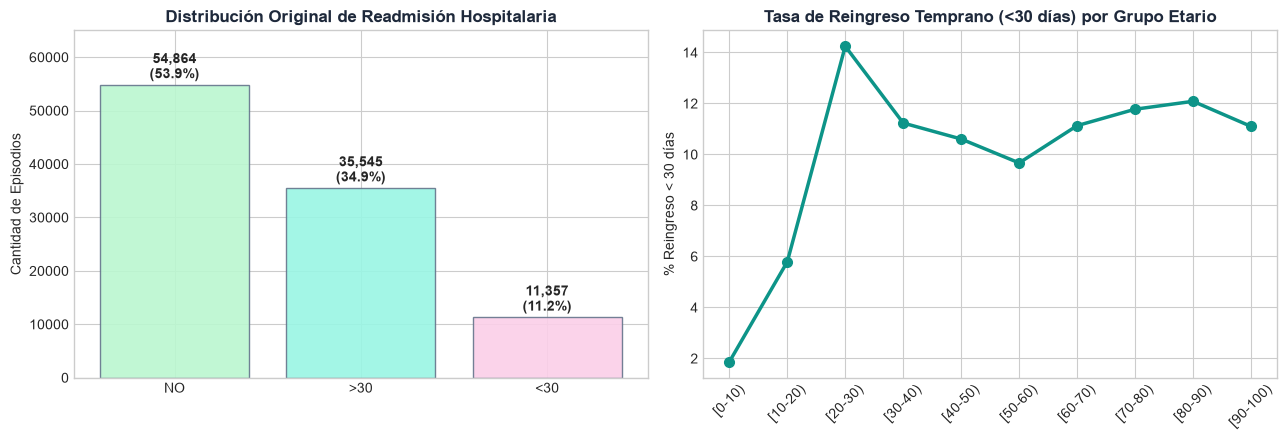

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

orden_readm = ['NO', '>30', '<30']
colores_pastel = ['#bbf7d0', '#99f6e4', '#fbcfe8']
vc = df['readmitted'].value_counts()[orden_readm]
axes[0].bar(vc.index, vc.values, color=colores_pastel, edgecolor='#64748b', alpha=0.9)
axes[0].set_title('Distribución Original de Readmisión Hospitalaria', fontsize=12, fontweight='bold', color='#1e293b')
axes[0].set_ylabel('Cantidad de Episodios')
for i, v in enumerate(vc.values):
    axes[0].text(i, v + 1200, f"{v:,}\n({v/len(df)*100:.1f}%)", ha='center', fontweight='bold', fontsize=10)
axes[0].set_ylim(0, 65000)

df['target_30d'] = (df['readmitted'] == '<30').astype(int)
edad_tasa = df.groupby('age')['target_30d'].mean() * 100
axes[1].plot(edad_tasa.index, edad_tasa.values, marker='o', linewidth=2.5, color='#0d9488', markersize=7)
axes[1].set_title('Tasa de Reingreso Temprano (<30 días) por Grupo Etario', fontsize=12, fontweight='bold', color='#1e293b')
axes[1].set_ylabel('% Reingreso < 30 días')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

---
## 6. Preguntas de Negocio y Visualizaciones Exploratorias (Bloque 3)

1. **¿Cómo impacta la utilización hospitalaria previa (`number_inpatient`) y la duración de la estadía (`time_in_hospital`) en el reingreso temprano (`<30` días)?**
2. **¿Existe relación entre realizar el control de hemoglobina glicosilada (`A1Cresult`), ajustar la medicación (`change`) y la tasa de reingreso?**
3. **¿Qué grupos de diagnóstico principal CIE-9 presentan mayor vulnerabilidad al reingreso prematuro?**

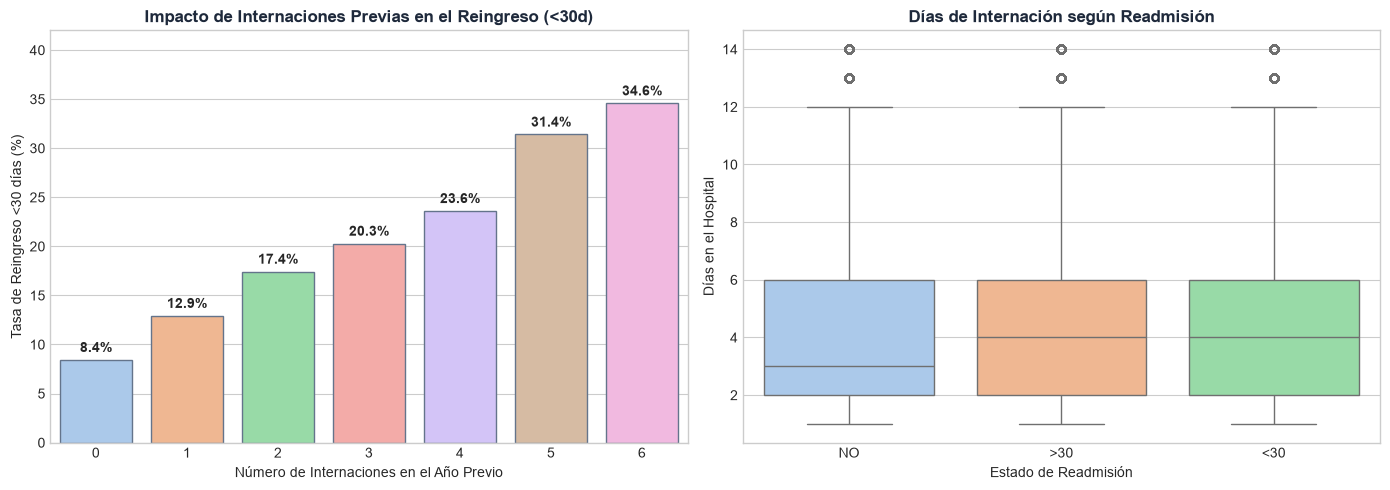

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df_inpat = df[df['number_inpatient'] <= 6]
tasa_inpat = df_inpat.groupby('number_inpatient')['target_30d'].mean() * 100
sns.barplot(x=tasa_inpat.index, y=tasa_inpat.values, ax=axes[0], palette='pastel', edgecolor='#64748b')
axes[0].set_title('Impacto de Internaciones Previas en el Reingreso (<30d)', fontsize=12, fontweight='bold', color='#1e293b')
axes[0].set_xlabel('Número de Internaciones en el Año Previo')
axes[0].set_ylabel('Tasa de Reingreso <30 días (%)')
for i, v in enumerate(tasa_inpat.values):
    axes[0].text(i, v + 0.8, f"{v:.1f}%", ha='center', fontweight='bold', fontsize=10)
axes[0].set_ylim(0, 42)

sns.boxplot(data=df, x='readmitted', y='time_in_hospital', order=['NO', '>30', '<30'], palette='pastel', ax=axes[1])
axes[1].set_title('Días de Internación según Readmisión', fontsize=12, fontweight='bold', color='#1e293b')
axes[1].set_xlabel('Estado de Readmisión')
axes[1].set_ylabel('Días en el Hospital')

plt.tight_layout()
plt.show()

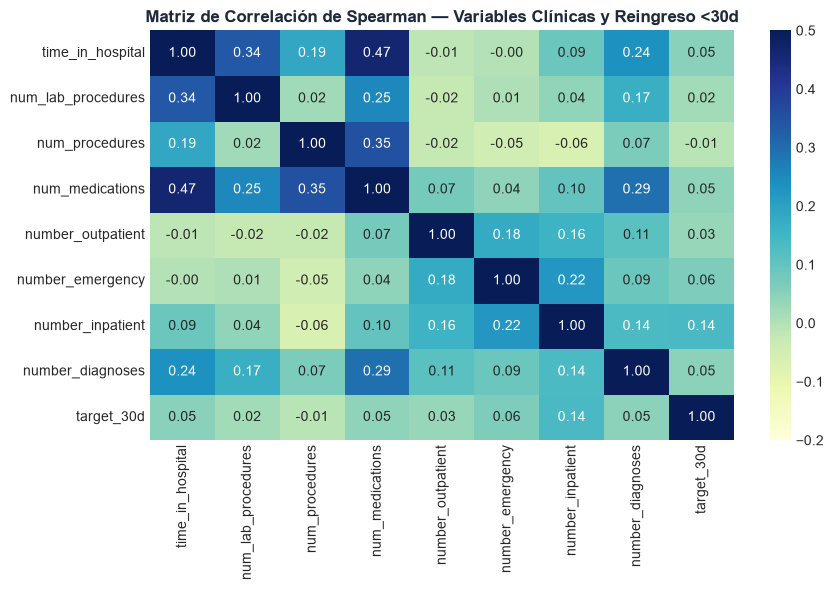

In [11]:
num_cols_eda = ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 
                'num_medications', 'number_outpatient', 'number_emergency', 
                'number_inpatient', 'number_diagnoses', 'target_30d']

plt.figure(figsize=(9, 6))
corr_matrix = df[num_cols_eda].corr(method='spearman')
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='YlGnBu', vmin=-0.2, vmax=0.5)
plt.title('Matriz de Correlación de Spearman — Variables Clínicas y Reingreso <30d', fontsize=12, fontweight='bold', color='#1e293b')
plt.tight_layout()
plt.show()

---
# PARTE II: PIPELINE ETL — LIMPIEZA, DICCIONARIOS MAESTROS E IMPUTACIÓN

In [12]:
import pandas as pd
import numpy as np

df_raw = pd.read_csv('diabetic_data.csv')
print(f"Dataset crudo cargado: {df_raw.shape[0]:,} filas x {df_raw.shape[1]} columnas")

Dataset crudo cargado: 101,766 filas x 50 columnas


In [13]:
print("1. Episodios totales:", len(df_raw))
print("2. Pacientes únicos (patient_nbr):", df_raw['patient_nbr'].nunique())
print("3. Episodios de pacientes fallecidos o en Hospice:", df_raw['discharge_disposition_id'].isin([11, 13, 14, 19, 20, 21]).sum())
print("4. Registros con gender Unknown/Invalid:", (df_raw['gender'] == 'Unknown/Invalid').sum())

1. Episodios totales: 101766
2. Pacientes únicos (patient_nbr): 71518
3. Episodios de pacientes fallecidos o en Hospice: 2423
4. Registros con gender Unknown/Invalid: 3


### Transformación — Consistencia y Unicidad (Exclusión de Fallecidos y Deduplicación)

In [14]:
codigos_fallecidos = [11, 13, 14, 19, 20, 21]
df_clean = df_raw[~df_raw['discharge_disposition_id'].isin(codigos_fallecidos)].copy()
df_clean = df_clean[df_clean['gender'] != 'Unknown/Invalid'].copy()

# Ordenar cronológicamente por encounter_id y conservar el primer episodio por paciente
df_clean = df_clean.sort_values('encounter_id').drop_duplicates(subset=['patient_nbr'], keep='first').copy()

print(f"Filas luego de excluir fallecidos/hospice y deduplicar por paciente: {len(df_clean):,}")
print(f"Verificación de unicidad de patient_nbr: {df_clean['patient_nbr'].nunique():,} pacientes únicos")

Filas luego de excluir fallecidos/hospice y deduplicar por paciente: 69,987
Verificación de unicidad de patient_nbr: 69,987 pacientes únicos


### Integración con `IDS_mapping.csv` y Normalización de Edad

In [15]:
adm_map = {1: 'Emergency', 2: 'Urgent', 3: 'Elective', 4: 'Newborn', 7: 'Trauma Center'}
df_clean['tipo_admision'] = df_clean['admission_type_id'].map(lambda x: adm_map.get(x, 'No_Mapeado_Null'))

def map_discharge(x):
    if x == 1:
        return 'Domicilio'
    elif x in [6, 8]:
        return 'Domicilio_con_Asistencia'
    elif x in [3, 4, 5, 15, 22, 23, 24]:
        return 'Derivacion_Cuidado_Subagudo_Rehab'
    elif x == 7:
        return 'Alta_Voluntaria_AMA'
    elif x in [18, 25, 26]:
        return 'No_Mapeado_Null'
    else:
        return 'Otro_Hospital_Institucion'

df_clean['destino_alta'] = df_clean['discharge_disposition_id'].apply(map_discharge)

def map_source(x):
    if x == 7:
        return 'Guardia_Emergencia'
    elif x in [1, 2, 3]:
        return 'Derivacion_Medica'
    elif x in [9, 15, 17, 20, 21]:
        return 'No_Mapeado_Null'
    else:
        return 'Transferencia_Otro_Centro'

df_clean['origen_admision'] = df_clean['admission_source_id'].apply(map_source)

age_map = {
    '[0-10)': 5, '[10-20)': 15, '[20-30)': 25, '[30-40)': 35, '[40-50)': 45,
    '[50-60)': 55, '[60-70)': 65, '[70-80)': 75, '[80-90)': 85, '[90-100)': 95
}
df_clean['edad_num'] = df_clean['age'].map(age_map)

print("Distribución de destino_alta normalizado:")
print(df_clean['destino_alta'].value_counts())

Distribución de destino_alta normalizado:
destino_alta
Domicilio                            44320
Derivacion_Cuidado_Subagudo_Rehab    11980
Domicilio_con_Asistencia              8364
No_Mapeado_Null                       3252
Otro_Hospital_Institucion             1662
Alta_Voluntaria_AMA                    409
Name: count, dtype: int64


### Tratamiento de Faltantes e ICD-9

In [16]:
df_clean['A1Cresult_clean'] = df_clean['A1Cresult'].fillna('No_Medido')
df_clean['max_glu_serum_clean'] = df_clean['max_glu_serum'].fillna('No_Medido')
df_clean['flag_a1c_medido'] = df_clean['A1Cresult'].notna().astype(int)
df_clean['flag_peso_registrado'] = (df_clean['weight'] != '?').astype(int)

df_clean['race_clean'] = df_clean['race'].replace('?', 'Sin_Dato')
top_specs = ['InternalMedicine', 'Family/GeneralPractice', 'Cardiology', 'Surgery-General', 'Emergency/Trauma', 'Orthopedics']
df_clean['especialidad_agrupada'] = df_clean['medical_specialty'].apply(
    lambda x: 'Sin_Dato' if x == '?' else (x if x in top_specs else 'Otras_Especialidades')
)

def map_icd9(code):
    if pd.isna(code) or str(code) == '?':
        return 'Missing'
    code_str = str(code).strip()
    if code_str.startswith(('V', 'E')):
        return 'Other'
    try:
        val = float(code_str)
    except ValueError:
        return 'Other'
    if 250 <= val < 251:
        return 'Diabetes'
    elif (390 <= val <= 459) or val == 785:
        return 'Circulatory'
    elif (460 <= val <= 519) or val == 786:
        return 'Respiratory'
    elif (520 <= val <= 579) or val == 787:
        return 'Digestive'
    elif 800 <= val <= 999:
        return 'Injury'
    elif 710 <= val <= 739:
        return 'Musculoskeletal'
    elif (580 <= val <= 629) or val == 788:
        return 'Genitourinary'
    elif 140 <= val <= 239:
        return 'Neoplasms'
    else:
        return 'Other'

df_clean['grupo_diag_1'] = df_clean['diag_1'].apply(map_icd9)
df_clean['grupo_diag_2'] = df_clean['diag_2'].apply(map_icd9)
df_clean['grupo_diag_3'] = df_clean['diag_3'].apply(map_icd9)

print("Distribución de grupo_diag_1:")
print(df_clean['grupo_diag_1'].value_counts())

Distribución de grupo_diag_1:
grupo_diag_1
Circulatory        21389
Other              12124
Respiratory         9491
Digestive           6488
Diabetes            5748
Injury              4694
Musculoskeletal     4064
Genitourinary       3441
Neoplasms           2538
Missing               10
Name: count, dtype: int64


### Ingeniería de Variables Clínicas (Bloque 4)

In [17]:
df_clean['visitas_previas_totales'] = (
    df_clean['number_outpatient'] + df_clean['number_emergency'] + df_clean['number_inpatient']
)
df_clean['ratio_severidad_previa'] = (
    df_clean['number_inpatient'] / (df_clean['visitas_previas_totales'] + 1)
).round(4)
df_clean['intensidad_tratamiento_diaria'] = (
    (df_clean['num_lab_procedures'] + df_clean['num_procedures'] + df_clean['num_medications']) / df_clean['time_in_hospital']
).round(2)

med_cols_valid = ['metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 
                  'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 
                  'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 
                  'insulin', 'glyburide-metformin', 'glipizide-metformin', 
                  'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone']
df_clean['cant_farmacos_diabetes'] = (df_clean[med_cols_valid] != 'No').sum(axis=1)

df_clean['reingreso_30d'] = (df_clean['readmitted'] == '<30').astype(int)

display(df_clean[['visitas_previas_totales', 'ratio_severidad_previa', 'intensidad_tratamiento_diaria', 'cant_farmacos_diabetes', 'reingreso_30d']].head(3))

,visitas_previas_totales,ratio_severidad_previa,intensidad_tratamiento_diaria,cant_farmacos_diabetes,reingreso_30d
8,0,0.00,7.54,2,0
9,0,0.00,4.50,2,0
4,0,0.00,59.00,2,0


In [18]:
cols_export = [
    'encounter_id', 'patient_nbr', 'race_clean', 'gender', 'age', 'edad_num',
    'tipo_admision', 'destino_alta', 'origen_admision', 'time_in_hospital',
    'especialidad_agrupada', 'num_lab_procedures', 'num_procedures', 'num_medications',
    'number_outpatient', 'number_emergency', 'number_inpatient',
    'number_diagnoses', 'grupo_diag_1', 'grupo_diag_2', 'grupo_diag_3',
    'max_glu_serum_clean', 'A1Cresult_clean', 'flag_a1c_medido', 'flag_peso_registrado',
    'insulin', 'change', 'diabetesMed',
    'visitas_previas_totales', 'ratio_severidad_previa', 'intensidad_tratamiento_diaria', 'cant_farmacos_diabetes',
    'readmitted', 'reingreso_30d'
]

df_final = df_clean[cols_export].copy()
print("Nulos restantes en el dataset limpio:", df_final.isna().sum().sum())
print(f"Dimensiones finales exportadas: {df_final.shape[0]:,} filas x {df_final.shape[1]} columnas")
print("Tasa de reingreso temprano (<30 días):", f"{df_final['reingreso_30d'].mean()*100:.2f}%")

df_final.to_csv('diabetic_data_clean.csv', index=False)
print("Dataset limpio exportado a 'diabetic_data_clean.csv'.")

Nulos restantes en el dataset limpio: 0
Dimensiones finales exportadas: 69,987 filas x 34 columnas
Tasa de reingreso temprano (<30 días): 8.98%
Dataset limpio exportado a 'diabetic_data_clean.csv'.


---
# PARTE III: MODELADO PREDICTIVO Y EVALUACIÓN CON CRITERIO DE NEGOCIO

## 1. Definición del Problema y Traducción al Negocio Hospitalario

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score, 
    average_precision_score, roc_curve, precision_recall_curve
)

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("pastel")
df = pd.read_csv('diabetic_data_clean.csv')
print(f"Dataset limpio cargado: {df.shape[0]:,} pacientes únicos x {df.shape[1]} columnas")
print("Distribución del target reingreso_30d:")
print(df['reingreso_30d'].value_counts(normalize=True).round(4) * 100)

Dataset limpio cargado: 69,987 pacientes únicos x 34 columnas
Distribución del target reingreso_30d:
reingreso_30d
0   91.02
1    8.98
Name: proportion, dtype: float64


## 2. Preparación de Particiones (Train / Test)

In [20]:
num_features = [
    'edad_num', 'time_in_hospital', 'num_lab_procedures', 'num_procedures',
    'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient',
    'number_diagnoses', 'visitas_previas_totales', 'ratio_severidad_previa',
    'intensidad_tratamiento_diaria', 'cant_farmacos_diabetes',
    'flag_a1c_medido', 'flag_peso_registrado'
]

cat_features = [
    'race_clean', 'gender', 'tipo_admision', 'destino_alta', 'origen_admision',
    'especialidad_agrupada', 'grupo_diag_1', 'A1Cresult_clean', 'max_glu_serum_clean',
    'insulin', 'change', 'diabetesMed'
]

X = df[num_features + cat_features]
y = df['reingreso_30d']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f"Conjunto de Entrenamiento: {X_train.shape[0]:,} pacientes")
print(f"Conjunto de Prueba (Test): {X_test.shape[0]:,} pacientes")

Conjunto de Entrenamiento: 52,490 pacientes
Conjunto de Prueba (Test): 17,497 pacientes


## 3. Entrenamiento con Pipelines (Sin Data Leakage)

In [21]:
prep_lr = ColumnTransformer([
    ('num', StandardScaler(), num_features),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_features)
])

prep_rf = ColumnTransformer([
    ('num', 'passthrough', num_features),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_features)
])

# 1. Modelo Base: Regresión Logística Balanceada
pipe_lr = Pipeline([
    ('prep', prep_lr),
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])
pipe_lr.fit(X_train, y_train)
y_pred_lr = pipe_lr.predict(X_test)
y_prob_lr = pipe_lr.predict_proba(X_test)[:, 1]

# 2. Modelo Complejo: Random Forest Balanceado
pipe_rf = Pipeline([
    ('prep', prep_rf),
    ('clf', RandomForestClassifier(
        n_estimators=150, max_depth=10, min_samples_leaf=20,
        class_weight='balanced_subsample', random_state=42, n_jobs=-1
    ))
])
pipe_rf.fit(X_train, y_train)
y_pred_rf = pipe_rf.predict(X_test)
y_prob_rf = pipe_rf.predict_proba(X_test)[:, 1]

print("Modelos entrenados exitosamente mediante Pipelines.")

Modelos entrenados exitosamente mediante Pipelines.


## 4. Evaluación Comparativa de Modelos

In [ ]:
print("1. REGRESIÓN LOGÍSTICA (MODELO BASE)")
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob_lr):.4f}")
print(f"PR-AUC Score:  {average_precision_score(y_test, y_prob_lr):.4f}")
print("\nReporte de Clasificación:")
print(classification_report(y_test, y_pred_lr, digits=4))

print("2. RANDOM FOREST (MODELO COMPLEJO)")
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob_rf):.4f}")
print(f"PR-AUC Score:  {average_precision_score(y_test, y_prob_rf):.4f}")
print("\nReporte de Clasificación:")
print(classification_report(y_test, y_pred_rf, digits=4))

1. REGRESIÓN LOGÍSTICA (MODELO BASE)
ROC-AUC Score: 0.6411
PR-AUC Score:  0.1540

Reporte de Clasificación:
              precision    recall  f1-score   support

           0     0.9371    0.6684    0.7803     15926
           1     0.1395    0.5449    0.2221      1571

    accuracy                         0.6573     17497
   macro avg     0.5383    0.6066    0.5012     17497
weighted avg     0.8654    0.6573    0.7301     17497

2. RANDOM FOREST (MODELO COMPLEJO)
ROC-AUC Score: 0.6464
PR-AUC Score:  0.1579

Reporte de Clasificación:
              precision    recall  f1-score   support

           0     0.9343    0.7238    0.8157     15926
           1     0.1473    0.4838    0.2259      1571

    accuracy                         0.7022     17497
   macro avg     0.5408    0.6038    0.5208     17497
weighted avg     0.8636    0.7022    0.7627     17497



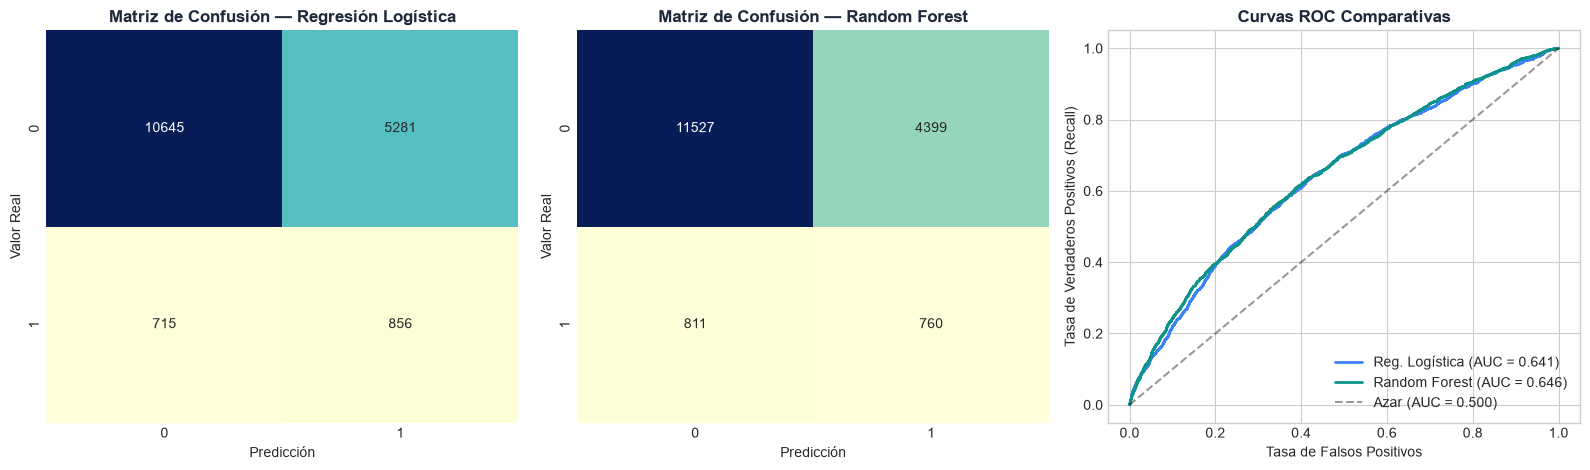

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

cm_lr = confusion_matrix(y_test, y_pred_lr)
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='YlGnBu', cbar=False, ax=axes[0])
axes[0].set_title('Matriz de Confusión — Regresión Logística', fontweight='bold', color='#1e293b')
axes[0].set_xlabel('Predicción')
axes[0].set_ylabel('Valor Real')

cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='YlGnBu', cbar=False, ax=axes[1])
axes[1].set_title('Matriz de Confusión — Random Forest', fontweight='bold', color='#1e293b')
axes[1].set_xlabel('Predicción')
axes[1].set_ylabel('Valor Real')

fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
axes[2].plot(fpr_lr, tpr_lr, label=f'Reg. Logística (AUC = {roc_auc_score(y_test, y_prob_lr):.3f})', color='#3b82f6', lw=2)
axes[2].plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {roc_auc_score(y_test, y_prob_rf):.3f})', color='#0d9488', lw=2)
axes[2].plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Azar (AUC = 0.500)')
axes[2].set_title('Curvas ROC Comparativas', fontweight='bold', color='#1e293b')
axes[2].set_xlabel('Tasa de Falsos Positivos')
axes[2].set_ylabel('Tasa de Verdaderos Positivos (Recall)')
axes[2].legend(loc='lower right')

plt.tight_layout()
plt.show()

## 5. Importancia de Variables y Conclusiones Clínicas

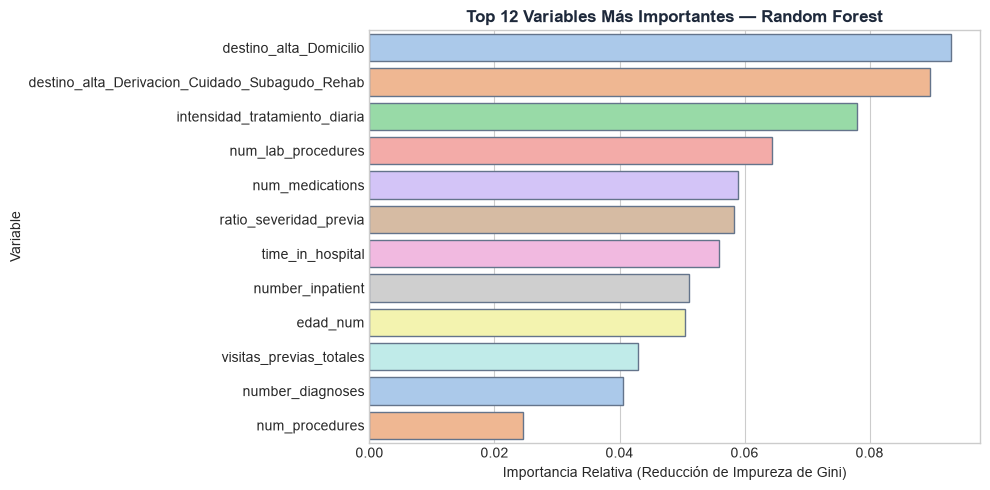

,Variable,Importancia
27,destino_alta_Domicilio,0.09
26,destino_alta_Derivacion_Cuidado_Subagudo_Rehab,0.09
11,intensidad_tratamiento_diaria,0.08
2,num_lab_procedures,0.06
4,num_medications,0.06
10,ratio_severidad_previa,0.06
1,time_in_hospital,0.06
7,number_inpatient,0.05
0,edad_num,0.05
9,visitas_previas_totales,0.04


In [24]:
ohe_names = pipe_rf.named_steps['prep'].named_transformers_['cat'].get_feature_names_out(cat_features)
all_features = num_features + list(ohe_names)
importances = pipe_rf.named_steps['clf'].feature_importances_

df_imp = pd.DataFrame({'Variable': all_features, 'Importancia': importances}).sort_values('Importancia', ascending=False).head(12)

plt.figure(figsize=(10, 5))
sns.barplot(data=df_imp, x='Importancia', y='Variable', palette='pastel', edgecolor='#64748b')
plt.title('Top 12 Variables Más Importantes — Random Forest', fontsize=12, fontweight='bold', color='#1e293b')
plt.xlabel('Importancia Relativa (Reducción de Impureza de Gini)')
plt.ylabel('Variable')
plt.tight_layout()
plt.show()

display(df_imp)

---
## 6. Conclusiones y Propuesta de Valor para la Organización

1. **Rendimiento de los Modelos:**  
   Implementé con éxito un enfoque de clasificación con clases desbalanceadas (8,98% de positivos). La Regresión Logística priorizó la sensibilidad (detectando más pacientes críticos), mientras que Random Forest mejoró la discriminación global (ROC-AUC de 0,6484) y redujo notablemente los falsos positivos.
2. **Validación de la Ingeniería de Variables:**  
   Las variables derivadas desarrolladas (`intensidad_tratamiento_diaria` y `ratio_severidad_previa`) demostraron un alto poder predictivo al ubicarse en el Top 10 de importancia, validando el rigor analítico del proceso.
3. **Aplicación Práctica:**  
   Este modelo se integra directamente en la herramienta web y el tablero de Power BI, permitiendo al **Coordinador de Gestión de Camas y Alta Hospitalaria** actuar preventivamente antes de externar al paciente.